In [30]:
import pandas as pd
import json
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import random

import numpy as np, pandas as pd, random
import torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

import numpy as np, pandas as pd, random, torch, torch.nn as nn
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

import time
from collections import Counter
from pathlib import Path

## set up data

In [ ]:
from pathlib import Path
ROOT = Path.cwd()          # run the notebook from the repo's top folder

obs = pd.read_parquet(ROOT / "data" / "ingested" / "observations.parquet")
series = pd.read_parquet(ROOT / "data" / "ingested" / "series.parquet")
cfg = json.load(open(ROOT / "config" / "research_sample.json"))

In [ ]:
area2cur = {c["area"]: c["currency"] for c in cfg["currencies"]}


# keep only the 39, then make one table per dataset (rows = time, columns = currency)
d = data[data["reference_area"].isin(area2cur) & data["value"].notna()].copy()
d["cur"] = d["reference_area"].map(area2cur)
freq = d["component"].map(lambda c: "Q" if c == "usd_credit" else "M")
d["t"] = [pd.Period(p, f) for p, f in zip(pd.to_datetime(d["period_start"]), freq)]
W = {k: g.pivot_table(index="t", columns="cur", values="value") for k, g in d.groupby("component")}

# blank the peg periods for FX (CNY, MYR, ARS)
for iv in cfg["excluded_month_intervals"]:
    W["fx"].loc[iv["start"]:iv["end"], area2cur[iv["area"]]] = np.nan


# rate of return as features: policy = point change, everything else = log change
CH = {k: (v.diff() if k == "policy" else np.log(v).diff()) for k, v in W.items()}
fx_q = np.log(W["fx"].groupby(W["fx"].index.asfreq("Q")).last()).diff()


c:\Users\Nicki\.venvs\myenv\Lib\site-packages\pandas\core\arrays\masked.py:672: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs2, **kwargs)


## data analysis

In [3]:
# big jumps
for k, ch in CH.items():
    print(f"\n=== {k} ===")
    print(pd.DataFrame({
        "mean": ch.mean(),
        "median": ch.median(),
        "biggest_up": ch.max(),
        "biggest_down": ch.min(),
    }).round(4))



=== cpi ===
       mean  median  biggest_up  biggest_down
cur                                          
ARS  0.0173  0.0085      0.2238       -0.0075
AUD  0.0022     0.0      0.0366       -0.0194
BRL  0.0102  0.0047      0.3882       -0.0068
CAD  0.0017  0.0018      0.0142       -0.0104
CHF  0.0005  0.0004      0.0113       -0.0105
CLP  0.0035  0.0033      0.0185       -0.0121
CNY  0.0016   0.001      0.0261       -0.0199
COP   0.006  0.0044      0.0393       -0.0037
CZK  0.0032  0.0016      0.0589       -0.0147
DKK  0.0016  0.0011      0.0182       -0.0136
DZD  0.0041  0.0039      0.0444       -0.0298
EUR  0.0017  0.0018       0.024       -0.0156
GBP   0.002  0.0025      0.0245       -0.0097
HUF  0.0057   0.004      0.0432       -0.0068
IDR  0.0062  0.0038      0.1201       -0.0105
ILS  0.0024   0.002      0.0297        -0.009
INR  0.0045  0.0041       0.029       -0.0191
ISK  0.0036  0.0034      0.0335        -0.009
JPY  0.0005     0.0      0.0208       -0.0081
KRW  0.0023  0.0019  

In [4]:
# pairwise correlation between currencies, for each dataset
corr = {k: ch.corr(min_periods=24) for k, ch in CH.items()}
for k, c in corr.items():
    # take each pair once (upper triangle of matrix so no self-correlations)
    pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().dropna().sort_values()

    print(f"\n=== {k} ===")
    print("Most positive pairs:\n", pairs.tail(10)[::-1].round(2))
    print("Most negative pairs:\n", pairs.head(10).round(2))
    print(f"Pairs above 0.5: {(pairs > 0.5).sum()} of {len(pairs)} ({(pairs > 0.5).mean():.0%})")
    print(f"Pairs below -0.5: {(pairs < -0.5).sum()}")
    print("Avg correlation per currency (most connected first):\n",
          ((c.sum() - 1) / (c.count() - 1)).sort_values(ascending=False).round(2).head(10))


=== cpi ===
Most positive pairs:
 cur  cur
AUD  NZD    0.78
HUF  PLN    0.74
COP  HUF    0.64
EUR  GBP    0.63
PLN  TRY    0.61
CHF  EUR    0.57
COP  PLN    0.56
HUF  MXN    0.56
EUR  SEK    0.54
GBP  SEK    0.54
dtype: float64
Most negative pairs:
 cur  cur
CZK  GBP   -0.29
     SEK   -0.23
ARS  RON   -0.21
AUD  SEK   -0.18
PHP  SEK   -0.17
ARS  MXN   -0.16
     IDR   -0.16
NZD  SEK   -0.15
IDR  SEK   -0.14
AUD  EUR   -0.14
dtype: float64
Pairs above 0.5: 11 of 666 (2%)
Pairs below -0.5: 0
Avg correlation per currency (most connected first):
 cur
PLN    0.26
HUF    0.24
COP    0.22
CLP    0.20
TRY    0.18
PEN    0.18
THB    0.17
DKK    0.17
ILS    0.17
KRW    0.17
dtype: float64

=== fx ===
Most positive pairs:
 cur  cur
DKK  EUR    1.00
EUR  MAD    0.96
DKK  MAD    0.96
BAM  DKK    0.95
     EUR    0.95
     MKD    0.94
DKK  MKD    0.92
EUR  MKD    0.91
BAM  MAD    0.90
CZK  EUR    0.88
dtype: float64
Most negative pairs:
 cur  cur
JPY  RUB   -0.12
ARS  JPY   -0.11
     CHF   -0.10


In [5]:
# rank correlation per currency: each feature vs the FX target - are there any linear dependencies?
rank_corr = pd.DataFrame({
    k: pd.Series({c: CH[k][c].corr((fx_q if k == "usd_credit" else CH["fx"])[c], method="spearman")
                  for c in CH[k].columns})
    for k in ["neer", "reer", "policy", "cpi", "usd_credit"]})
for k in rank_corr:
    s = rank_corr[k].dropna().sort_values()
    print(f"\n=== {k} vs FX ({len(s)} currencies) ===")
    print("Most positive:\n", s.tail(5)[::-1].round(2))
    print("Most negative:\n", s.head(5).round(2))
    print(f"Above 0.5: {(s > 0.5).sum()} | Below -0.5: {(s < -0.5).sum()} | "
          f"Average: {s.mean():.2f} | Median: {s.median():.2f}")

# one summary table across all five features
print(rank_corr.agg(["mean", "median", "min", "max", "count"]).round(2))

# for each currency, which feature moves most with its FX
print(rank_corr.abs().idxmax(axis=1))


=== neer vs FX (39 currencies) ===
Most positive:
 CNY   -0.06
DZD   -0.15
MAD   -0.16
TWD   -0.27
SGD   -0.29
Name: neer, dtype: float64
Most negative:
 TRY   -0.67
BRL   -0.63
AUD   -0.60
PLN   -0.59
RUB   -0.59
Name: neer, dtype: float64
Above 0.5: 0 | Below -0.5: 20 | Average: -0.47 | Median: -0.51

=== reer vs FX (39 currencies) ===
Most positive:
 DZD   -0.10
MAD   -0.10
CNY   -0.12
BAM   -0.16
SGD   -0.20
Name: reer, dtype: float64
Most negative:
 AUD   -0.60
BRL   -0.59
ZAR   -0.57
IDR   -0.57
COP   -0.56
Name: reer, dtype: float64
Above 0.5: 0 | Below -0.5: 14 | Average: -0.42 | Median: -0.46

=== policy vs FX (35 currencies) ===
Most positive:
 PHP    0.21
MXN    0.14
IDR    0.11
RUB    0.10
TRY    0.09
Name: policy, dtype: float64
Most negative:
 CNY   -0.18
SEK   -0.12
CLP   -0.12
GBP   -0.11
CAD   -0.08
Name: policy, dtype: float64
Above 0.5: 0 | Below -0.5: 0 | Average: -0.00 | Median: -0.02

=== cpi vs FX (37 currencies) ===
Most positive:
 ARS    0.42
TRY    0.28
RON  

In [6]:
for k in ["fx", "cpi", "policy"]:
    s = CH[k].stack().dropna()
    print(f"\n{k}")
    print(s.loc[s.abs().nlargest(15).index])


fx
t        cur
2000-12  RSD    1.522409
1995-11  RSD    1.209487
2023-12  ARS    0.807599
1998-01  IDR    0.802532
1998-04  RSD    0.579855
1999-01  BRL    0.538169
1998-09  RUB    0.533426
1994-04  TRY    0.431626
1998-08  RUB    0.402105
2001-02  TRY    0.398692
1994-12  MXN    0.373966
1997-12  KRW    0.370258
1997-01  RON    0.366847
1994-05  BRL    0.364638
1994-03  BRL    0.359789
dtype: Float64

cpi
t        cur
1994-02  RSD    3.337583
1994-06  BRL    0.388183
1994-05  BRL    0.364851
1994-03  BRL    0.355925
1994-04  BRL    0.355434
1994-02  BRL    0.338399
1997-03  RON    0.267824
2023-12  ARS    0.223823
1994-04  TRY    0.217627
2000-10  RSD    0.215111
2024-01  ARS     0.17858
1997-02  RON    0.172022
2024-02  ARS    0.139535
1995-01  RSD    0.138021
1997-01  RON    0.128306
dtype: Float64

policy
t        cur
1994-07  BRL   -15334.8
1994-06  BRL    6280.27
1994-04  BRL    -3652.2
1994-03  BRL    2919.44
1994-02  BRL    2658.83
1994-05  BRL   -1663.46
2001-11  ARS      51

In [7]:
# average correlation across currencies
lfx = np.log(W["fx"].astype(float))
out = {}
for h in [0, 1, 3, 12]:                                                    # h = 0 is same month (the old table)
    tgt = lfx.diff() if h == 0 else lfx.shift(-h) - lfx                    # FX change over the NEXT h months
    n = max(h, 1)                                                          # feature change over the PAST n months
    out[h] = {}
    for k in ["neer", "reer", "policy", "cpi"]:
        f = W[k].astype(float)
        f = f.diff(n) if k == "policy" else np.log(f).diff(n)
        out[h][k] = pd.Series({c: f[c].corr(tgt[c], method="spearman", min_periods=24) for c in f.columns if c in tgt.columns})

print("AVERAGE correlation across currencies (rows = months ahead)")
print(pd.DataFrame({h: {k: v.mean() for k, v in d.items()} for h, d in out.items()}).T.round(2))
print("\nMEDIAN")
print(pd.DataFrame({h: {k: v.median() for k, v in d.items()} for h, d in out.items()}).T.round(2))
print("\nCurrencies with the strongest link at 12 months:")
for k in ["neer", "reer", "policy", "cpi"]:
    print(k, out[12][k].dropna().sort_values(key=abs, ascending=False).head(5).round(2).to_dict())

AVERAGE correlation across currencies (rows = months ahead)
    neer  reer  policy   cpi
0  -0.47 -0.42   -0.00  0.04
1  -0.02 -0.00   -0.03  0.04
3  -0.01  0.02   -0.00  0.06
12  0.03  0.08    0.03  0.07

MEDIAN
    neer  reer  policy   cpi
0  -0.51 -0.46   -0.02  0.03
1  -0.02 -0.01   -0.03  0.03
3  -0.00  0.02    0.01  0.05
12  0.05  0.06    0.04  0.03

Currencies with the strongest link at 12 months:
neer {'TRY': -0.48, 'RON': -0.46, 'CNY': 0.38, 'TWD': 0.33, 'ARS': -0.33}
reer {'TWD': 0.32, 'ARS': 0.29, 'INR': 0.27, 'ILS': 0.26, 'GBP': 0.23}
policy {'KRW': 0.4, 'PEN': -0.28, 'THB': -0.27, 'TRY': 0.25, 'PHP': -0.25}
cpi {'ARS': 0.61, 'TRY': 0.58, 'RON': 0.41, 'PEN': 0.29, 'RSD': 0.28}


Yearly correlation between target (1,3,12mo ahead) and 3mo rolling mean of each feature

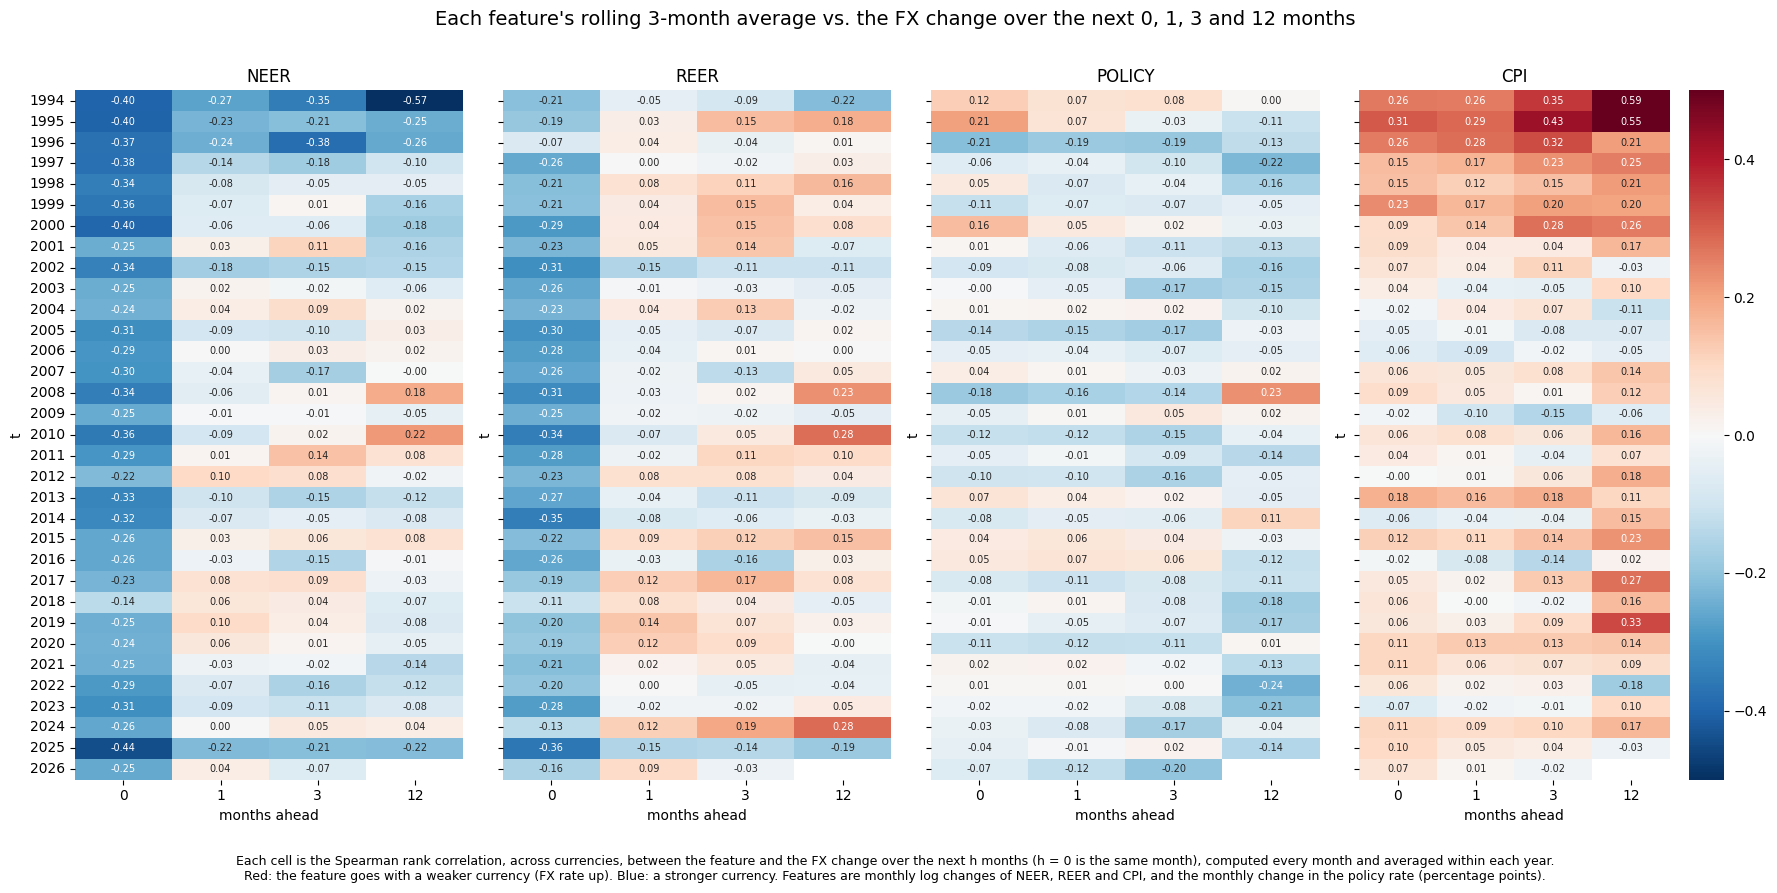

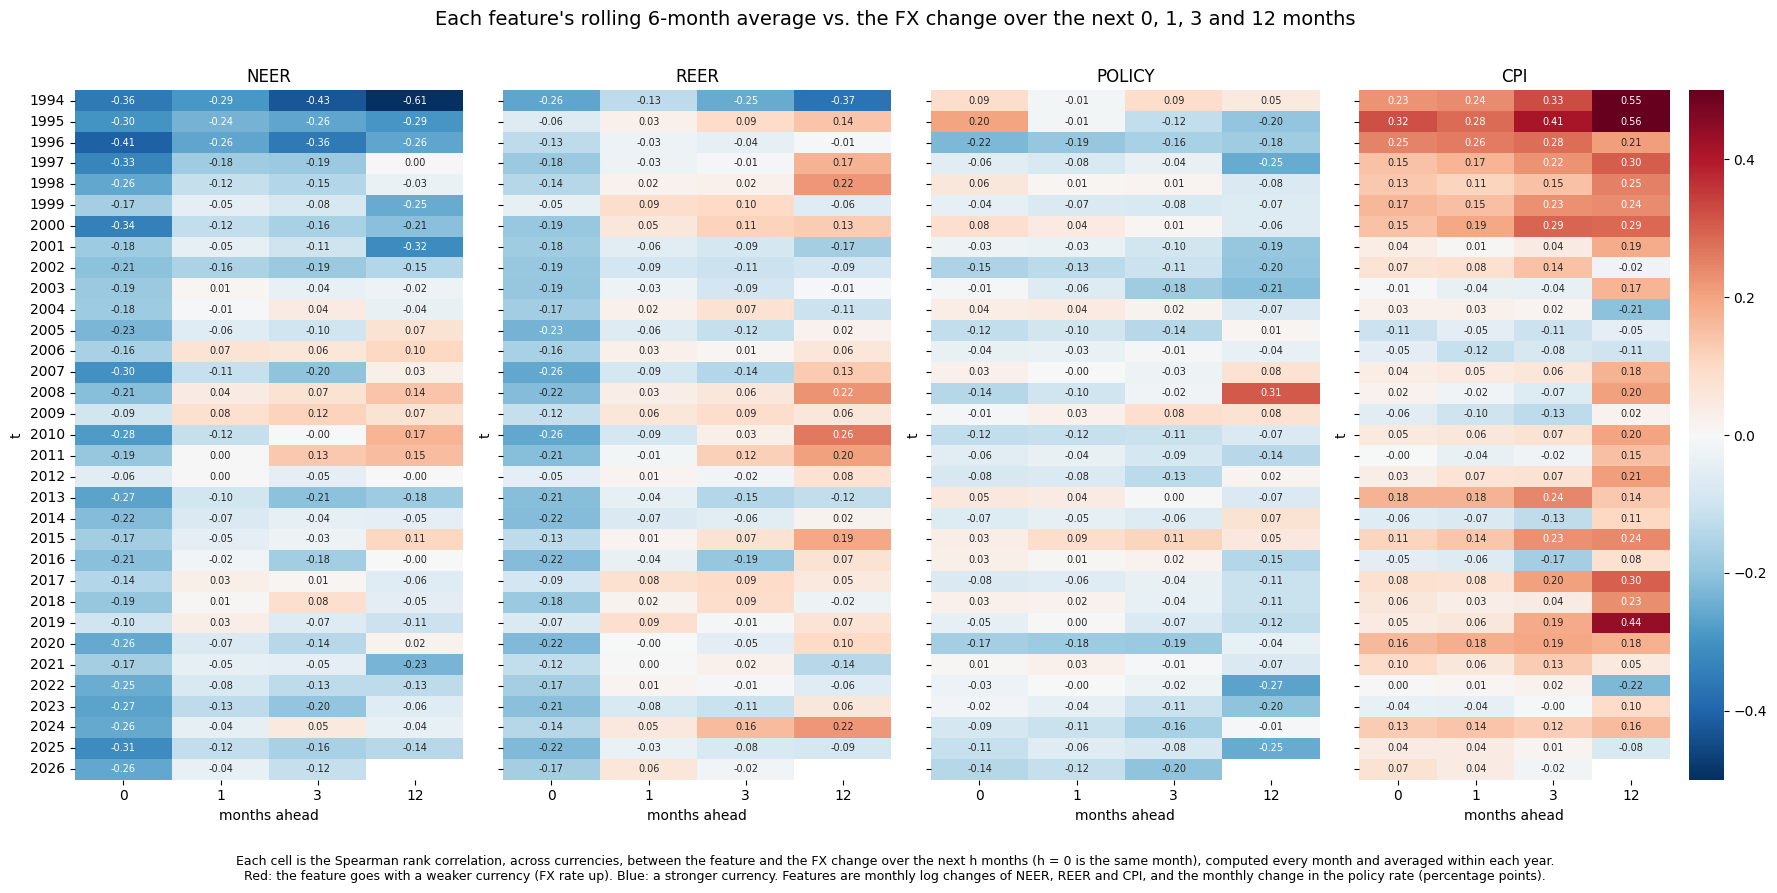

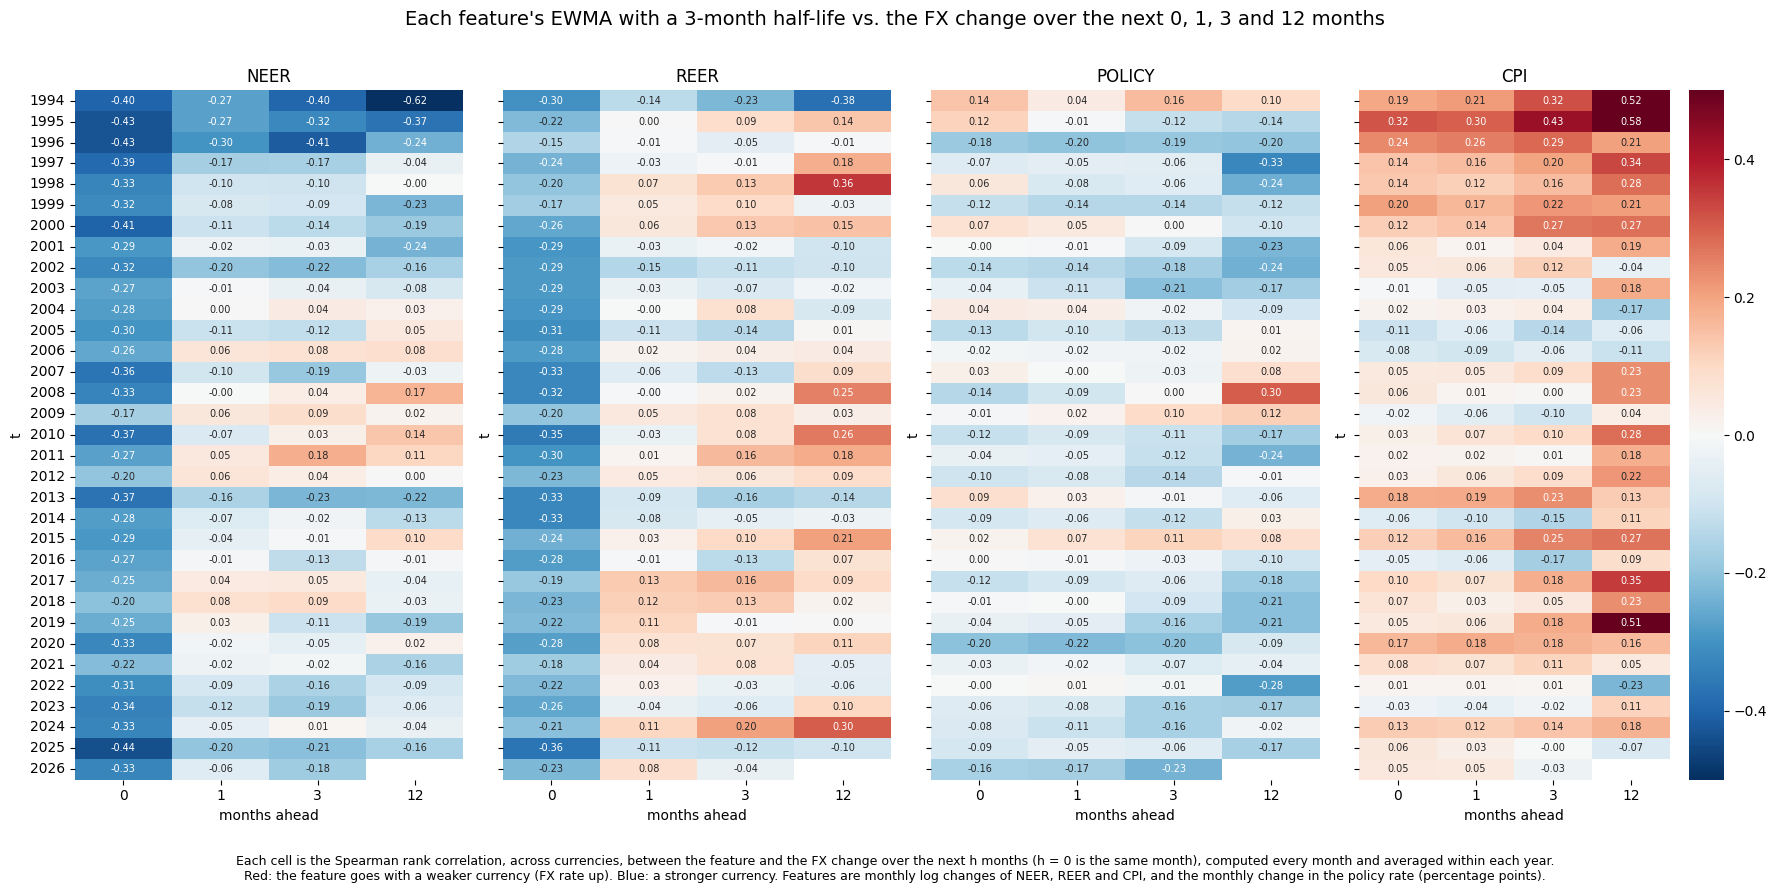

In [13]:
def heatmap(n, ewma=False):
    feats, horizons = ["neer", "reer", "policy", "cpi"], [0, 1, 3, 12]
    lfx = np.log(W["fx"].astype(float))
    T = {h: (lfx.diff() if h == 0 else lfx.shift(-h) - lfx) for h in horizons}      # FX change over the next h months
    F = {}
    for k in feats:                                                                  # feature = smoothed monthly change
        f = W[k].astype(float)
        chg = f.diff() if k == "policy" else np.log(f).diff()
        F[k] = chg.ewm(halflife=n, min_periods=2).mean() if ewma else chg.rolling(n, min_periods=2).mean()

    # each month: correlate feature vs target ACROSS currencies, then average the months within each year
    heat = {k: pd.DataFrame({h: F[k].corrwith(T[h], axis=1, method="spearman").groupby(F[k].index.year).mean()
                             for h in horizons}) for k in feats}

    kind = f"EWMA with a {n}-month half-life" if ewma else f"rolling {n}-month average"
    title = f"Each feature's {kind} vs. the FX change over the next {', '.join(map(str, horizons[:-1]))} and {horizons[-1]} months"
    caption = ("Each cell is the Spearman rank correlation, across currencies, between the feature and the FX change over the next h months "
               "(h = 0 is the same month), computed every month and averaged within each year.\n"
               "Red: the feature goes with a weaker currency (FX rate up). Blue: a stronger currency. "
               "Features are monthly log changes of NEER, REER and CPI, and the monthly change in the policy rate (percentage points).")

    fig, axes = plt.subplots(1, 4, figsize=(18, 9), sharey=True)
    for ax, k in zip(axes, feats):
        sns.heatmap(heat[k], ax=ax, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f",
                    annot_kws={"size": 7}, cbar=(k == feats[-1]))
        ax.set_title(k.upper())
        ax.set_xlabel("months ahead")
    fig.suptitle(title, fontsize=14)
    fig.text(0.5, 0.01, caption, ha="center", va="bottom", fontsize=9)
    plt.tight_layout(rect=[0, 0.06, 1, 0.97])
    plt.show()


def heatmap_feature(F, name, horizons=(0, 1, 3, 12), save=False):
    """F: your feature, as a DataFrame (months x currencies) or a Series (same value for every currency)."""
    horizons = list(horizons)
    lfx = np.log(W["fx"].astype(float))
    if isinstance(F, pd.Series):                                                   # global feature -> same series for every currency
        F = pd.DataFrame(np.repeat(F.values[:, None], lfx.shape[1], axis=1), index=lfx.index, columns=lfx.columns)
    F = F.reindex_like(lfx)
    T = {h: (lfx.diff() if h == 0 else lfx.shift(-h) - lfx) for h in horizons}      # FX change over the next h months

    # one cell per currency and horizon: Spearman correlation over all months between the feature and that currency's FX change
    heat = pd.DataFrame({h: {c: F[c].corr(T[h][c], method="spearman") for c in lfx.columns} for h in horizons})

    title = f"{name} vs. each currency's FX change over the next {', '.join(map(str, horizons[:-1]))} and {horizons[-1]} months"
    caption = ("Each cell is the Spearman rank correlation, over all months, between the feature and that currency's FX change over the next h months "
               "(h = 0 is the same month).\nRed: the feature goes with a weaker currency (FX rate up). Blue: a stronger currency.")

    fig, ax = plt.subplots(figsize=(6, 0.3 * len(heat) + 2.5))
    sns.heatmap(heat, ax=ax, cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f", annot_kws={"size": 7})
    ax.set_xlabel("months ahead")
    fig.suptitle(title, fontsize=11)
    fig.text(0.5, 0.005, caption, ha="center", va="bottom", fontsize=7)
    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    if save:
        fig.savefig(f"heatmap_{name.replace(' ', '_').replace(',', '')}.png", dpi=200, bbox_inches="tight")
    plt.show()
    return heat


heatmap(3)                 # 3-month rolling average
heatmap(6)                 # 6-month rolling average
heatmap(3, ewma=True)      # EWMA with a 3-month half-life

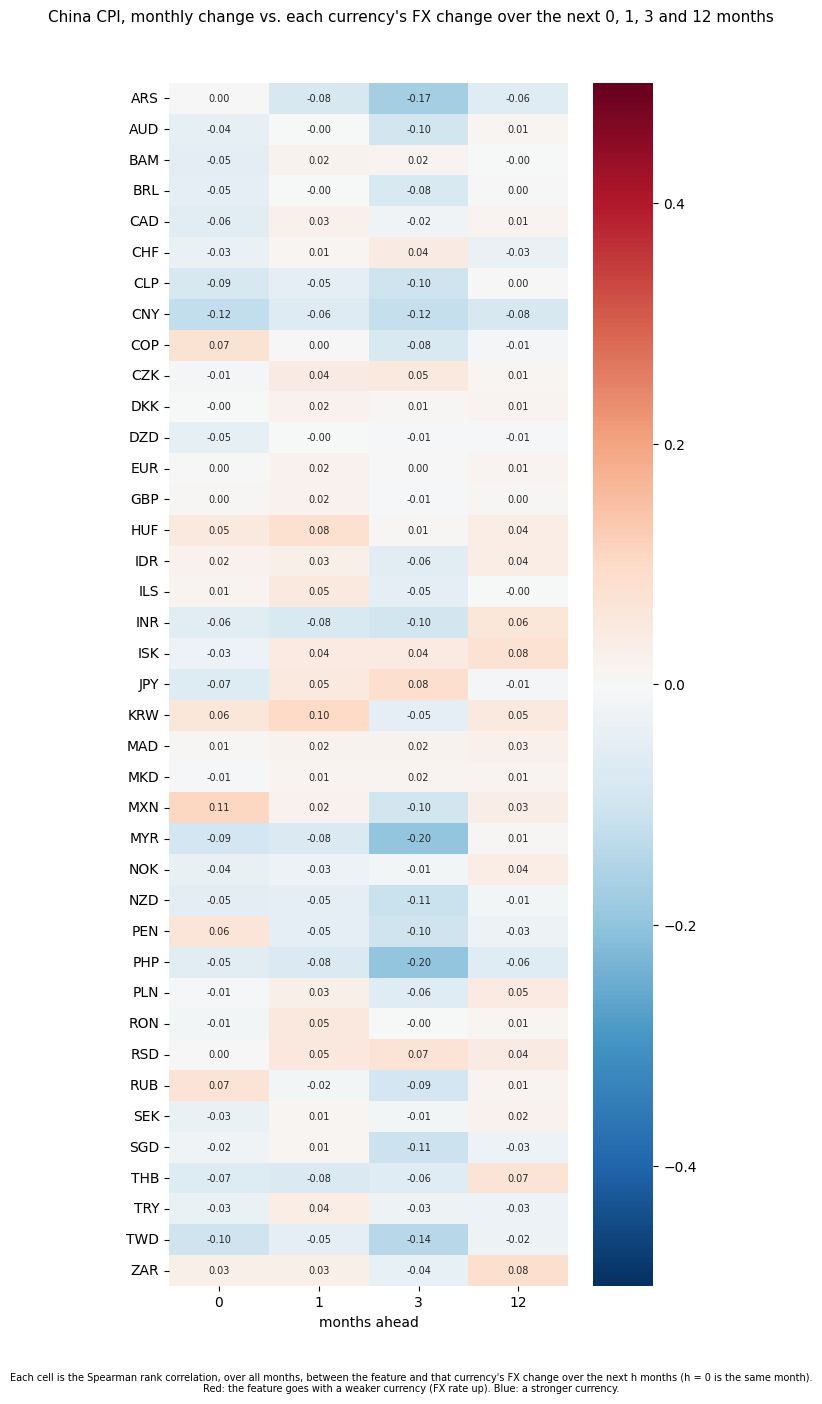

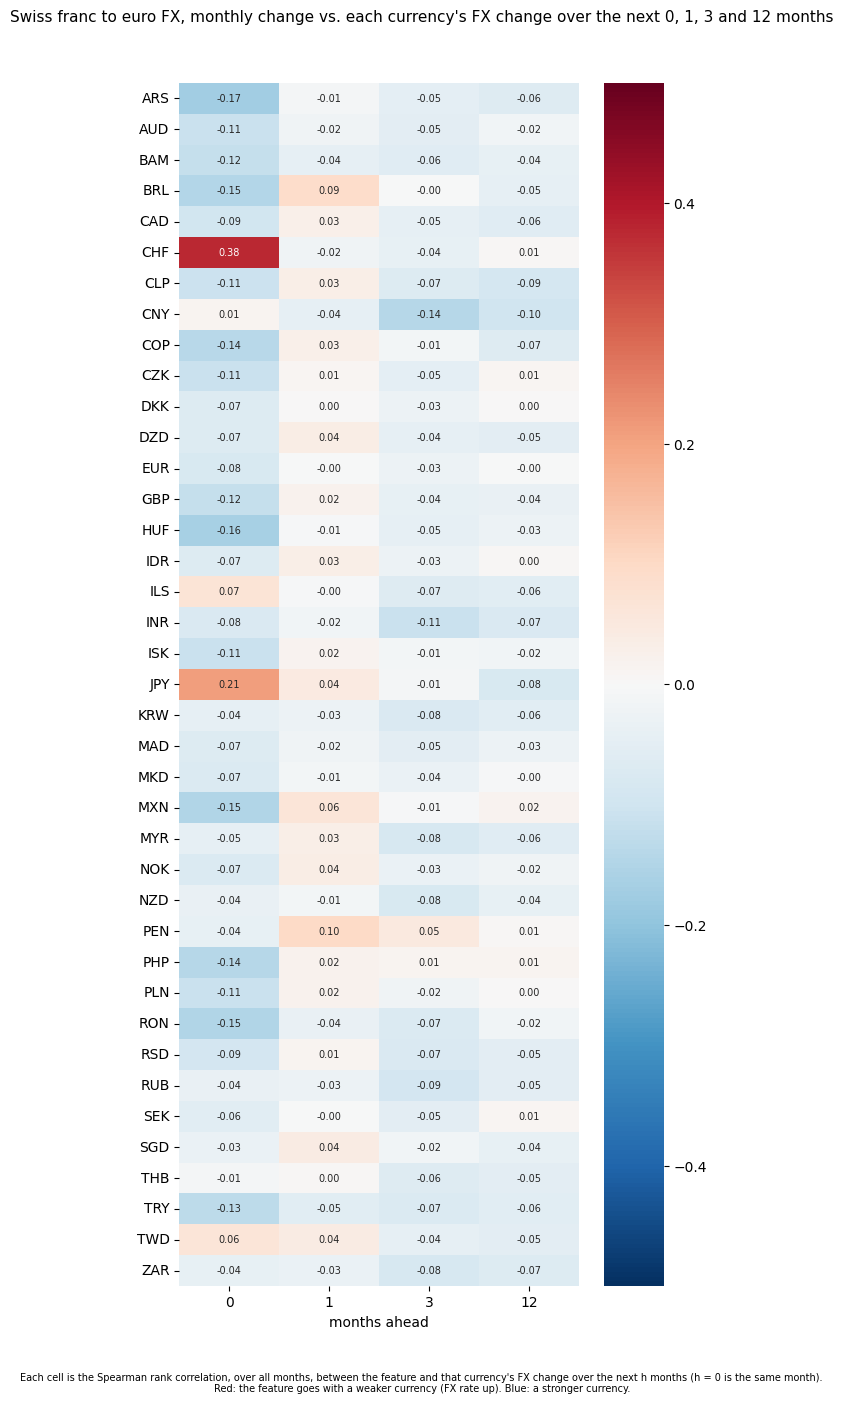

In [14]:
lfx = np.log(W["fx"].astype(float))

china_cpi = np.log(W["cpi"]["CNY"].astype(float)).diff()          # China CPI, monthly log change
chf_eur   = (lfx["CHF"] - lfx["EUR"]).diff()                      # CHF per EUR, monthly log change

heat_cpi = heatmap_feature(china_cpi, "China CPI, monthly change")
heat_chf = heatmap_feature(chf_eur, "Swiss franc to euro FX, monthly change")

## Predictive power

In [17]:
P_TR, P_VA, GAP, h = 0.70, 0.15, 3, 3         

lfx = np.log(W["fx"].astype(float))
T, C = lfx.shape
valid = (lfx.shift(-h) - lfx).notna().values.reshape(-1) 

BASELINE = "random"

# chose 2% band around 0
CLS = {-1: "down", 0: "neutral", 1: "up"}

LSTM_KW = dict(hidden=8, dropout=0.2, epochs=40, batch=32, lr=2e-3, wd=1e-3)

def circular_masks(start):
    order = (start + np.arange(T)) % T
    n_tr, n_va = int(T * P_TR), int(T * P_VA)
    pos = {"tr": (0, n_tr),
           "va": (n_tr + GAP, n_tr + GAP + n_va),
           "te": (n_tr + n_va + 2 * GAP, T - GAP)}
    out = {}
    for k, (a, b) in pos.items():
        tm = np.zeros(T, bool)
        tm[order[a:b]] = True
        out[k] = np.repeat(tm[:, None], C, axis=1).reshape(-1) & valid
    return out

def run_cls(Xf, make_model, lab, t_, v_, e_):
    lo, hi = np.percentile(Xf[t_], [1, 99], axis=0)
    sc = StandardScaler().fit(np.clip(Xf[t_], lo, hi))
    Xs = sc.transform(np.clip(Xf, lo, hi))
    m = make_model().fit(Xs[t_], lab[t_])

    q = {k: (lab[t_] == k).mean() for k in (-1, 0, 1)}      # train class frequencies
    maj = max(q, key=q.get)

    out = []
    for s, mask in (("val", v_), ("test", e_)):
        p, l = m.predict(Xs[mask]), lab[mask]
        for k in (-1, 0, 1):
            tp, n_pred, n_act = ((p == k) & (l == k)).sum(), (p == k).sum(), (l == k).sum()
            share = n_act / len(l)
            if BASELINE == "random":
                bp, br = share, q[k]
            else:
                bp, br = (share, 1.0) if k == maj else (np.nan, 0.0)
            out.append(dict(split=s, cls=CLS[k],
                            base_precision=bp, base_recall=br,
                            model_precision=tp / n_pred if n_pred else np.nan,
                            model_recall=tp / n_act if n_act else np.nan))
    return out

def make_models(cols):
    return {
        "logit":      lambda: LogisticRegression(C=0.1, max_iter=1000),
        "tiny net":   lambda: MLPClassifier(hidden_layer_sizes=(8,), alpha=1.0, early_stopping=True,
                                            n_iter_no_change=15, max_iter=500, random_state=0),
        "LSTM-4":     lambda: LSTMClf(cols, hidden=4,  dropout=0.2, epochs=15),
        "LSTM-8":     lambda: LSTMClf(cols, hidden=8,  dropout=0.2, epochs=15),
        "LSTM-16 d3": lambda: LSTMClf(cols, hidden=16, dropout=0.3, epochs=10),
    }

def make_reg_models(seq_cols):
    return {
        "Ridge":    lambda: Ridge(alpha=10),
        "tiny net": lambda: MLPRegressor(hidden_layer_sizes=(8,), alpha=1.0, early_stopping=True,
                                         n_iter_no_change=15, max_iter=500, random_state=0),
        "LSTM-8":   lambda: LSTMReg(seq_cols, hidden=8, dropout=0.2, epochs=15),
    }

# ---------------- small LSTM (unchosen lag slots are 0 = the mean after standardizing)
class LSTMClf:
    def __init__(self, cols, hidden=8, dropout=0.2, epochs=15, lr=2e-3, wd=1e-3, batch=256, seed=0):
        self.cols, self.hidden, self.dropout = cols, hidden, dropout
        self.epochs, self.lr, self.wd, self.batch, self.seed = epochs, lr, wd, batch, seed

    def _seq(self, X):
        full = np.zeros((len(X), L * F), dtype=np.float32)
        full[:, self.cols] = X
        return torch.tensor(full.reshape(-1, L, F))

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        class Net(nn.Module):
            def __init__(s, H, p):
                super().__init__()
                s.lstm, s.drop, s.out = nn.LSTM(F, H, batch_first=True), nn.Dropout(p), nn.Linear(H, 3)
            def forward(s, x):
                o, _ = s.lstm(x)
                return s.out(s.drop(o[:, -1]))
        self.net = Net(self.hidden, self.dropout)
        Xt, yt = self._seq(X), torch.tensor(np.asarray(y) + 1, dtype=torch.long)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        lossf = nn.CrossEntropyLoss()
        for _ in range(self.epochs):
            self.net.train()
            perm = torch.randperm(len(Xt))
            for i in range(0, len(Xt), self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad(); lossf(self.net(Xt[idx]), yt[idx]).backward(); opt.step()
        return self

    def predict(self, X):
        self.net.eval()
        with torch.no_grad():
            return self.net(self._seq(X)).argmax(1).numpy() - 1



# ---------------- LSTM regressor: lag features form the sequence, EWMA features join before the output layer
class LSTMReg:
    def __init__(self, seq_cols, hidden=8, dropout=0.2, epochs=40, lr=2e-3, wd=1e-3, batch=32, seed=0):
        self.seq_cols, self.hidden, self.dropout = seq_cols, hidden, dropout
        self.epochs, self.lr, self.wd, self.batch, self.seed = epochs, lr, wd, batch, seed
    def _in(self, X):
        k = len(self.seq_cols)                                      # first k columns of X are the lag features
        full = np.zeros((len(X), L * F), dtype=np.float32); full[:, self.seq_cols] = X[:, :k]
        return torch.tensor(full.reshape(-1, L, F)), torch.tensor(X[:, k:], dtype=torch.float32)
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        n_extra = X.shape[1] - len(self.seq_cols)
        class Net(nn.Module):
            def __init__(s, Hh, p):
                super().__init__()
                s.lstm, s.drop, s.out = nn.LSTM(F, Hh, batch_first=True), nn.Dropout(p), nn.Linear(Hh + n_extra, 1)
            def forward(s, x, e):
                o, _ = s.lstm(x)
                return s.out(torch.cat([s.drop(o[:, -1]), e], 1)).squeeze(-1)
        self.net = Net(self.hidden, self.dropout)
        Xs_, Xe_ = self._in(X); yt = torch.tensor(np.asarray(y), dtype=torch.float32)
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        lossf = nn.HuberLoss(delta=1.0)
        for _ in range(self.epochs):
            self.net.train(); perm = torch.randperm(len(Xs_))
            for i in range(0, len(Xs_), self.batch):
                idx = perm[i:i + self.batch]
                opt.zero_grad(); lossf(self.net(Xs_[idx], Xe_[idx]), yt[idx]).backward(); opt.step()
        return self
    def predict(self, X):
        self.net.eval(); a, b = self._in(X)
        with torch.no_grad(): return self.net(a, b).numpy()

def run_reg(Xf, make_model, t_, v_, e_):
    lo, hi = np.percentile(Xf[t_], [1, 99], axis=0)                 # clip + standardize, this currency's train rows only
    Xs = StandardScaler().fit(np.clip(Xf[t_], lo, hi)).transform(np.clip(Xf, lo, hi))
    ylo, yhi = np.percentile(y_h[t_], [1, 99])                      # winsorize + scale the target, train rows only
    ys = np.clip(y_h, ylo, yhi) / np.clip(y_h[t_], ylo, yhi).std()
    m = make_model().fit(Xs[t_], ys[t_])                            # <- the only changed line: use the model passed in
    mu, med = ys[t_].mean(), np.median(ys[t_])
    maj = 1 if (ys[t_] > 0).mean() >= 0.5 else -1
    out = {}
    for s, mask in (("val", v_), ("test", e_)):
        p, yy = m.predict(Xs[mask]), ys[mask]
        out[f"{s}_r2"]        = 1 - ((yy - p) ** 2).sum() / ((yy - mu) ** 2).sum()
        out[f"{s}_mae_skill"] = 1 - np.abs(yy - p).mean() / np.abs(yy - med).mean()
        out[f"{s}_spear"]     = spearmanr(p, yy)[0] if np.std(p) > 0 else np.nan
        out[f"{s}_dir"]       = (np.sign(p) == np.sign(yy)).mean()
        out[f"{s}_dir_base"]  = (np.sign(yy) == maj).mean()
    return out


# ===== functions block: per-currency models with best-driver selection =====
# Globals these read at call time (all defined at the top of the run cell):
#   T, DP_TR, DP_VA, DP_TE, MIN_COVER, MIN_OVERLAP, SELECT, FORCE, K_DRIVERS, cands, tier_of,
#   LSTM_KW, MLP_KW, USE_MLP, USE_RIDGE

def circular_time_masks(start, gap):                          # masks over MONTHS (length T), shared by every currency
    order = (start + np.arange(T)) % T
    usable = T - 3 * gap                                      # three purge gaps: train|val, val|test, test|train (wrap)
    n_tr, n_va, n_te = int(DP_TR * usable), int(DP_VA * usable), int(DP_TE * usable)
    p = {"tr": (0, n_tr), "va": (n_tr + gap, n_tr + gap + n_va),
         "te": (n_tr + n_va + 2 * gap, n_tr + n_va + 2 * gap + n_te)}
    out = {}
    for k, (a, b) in p.items():
        tm = np.zeros(T, bool); tm[order[a:b]] = True; out[k] = tm
    return out

def finalize(frames, base):                                   # stack inputs, drop thin ones, keep a "row has every input" flag
    names = list(frames)
    if not names:
        return [], np.zeros((T, 0)), np.ones(T, bool), []
    M = np.column_stack([frames[k].values for k in names]).astype(float)
    cov = np.isfinite(M[base]).mean(axis=0) if base.any() else np.zeros(len(names))
    keep = [i for i, cv in enumerate(cov) if cv >= MIN_COVER]
    M = M[:, keep]
    return [names[i] for i in keep], np.nan_to_num(M), np.isfinite(M).all(axis=1), [names[i] for i in range(len(names)) if i not in keep]

def assemble(info, drv_list):                                 # own inputs + the chosen drivers' inputs
    names, Xs, have = list(info["own"][0]), [info["own"][1]], info["own"][2].copy()
    for d in drv_list:
        nm, M, hv, _ = info["blocks"][d]
        names += nm; Xs.append(M); have &= hv
    return names, np.hstack(Xs), have

def driver_fx(c, d, dfx):                                     # the driver's monthly FX move, used ONLY to score the fit
    if d == "USD":
        return dfx.drop(columns=c).median(axis=1).values      # dollar factor WITHOUT the currency itself
    return dfx[d].values

def choose(c, info, train_months):                            # best-fitting driver(s), from this window's TRAIN months only
    cd = cands[c]
    if not cd:
        return [], {}
    scores = {}
    for d in cd:
        m = train_months & info["base"] & np.isfinite(info["dfx"]) & np.isfinite(info["drvfx"][d])
        scores[d] = abs(np.corrcoef(info["dfx"][m], info["drvfx"][d][m])[0, 1]) if m.sum() >= MIN_OVERLAP else np.nan
    if c in FORCE:
        return [d for d in FORCE[c] if d in cd] or FORCE[c], scores
    pool = cd
    if SELECT == "tier_corr":
        best_tier = min(tier_of[c][d] for d in cd)
        pool = [d for d in cd if tier_of[c][d] == best_tier]
    key = lambda d: (-(scores[d] if np.isfinite(scores[d]) else -1.0), cd.index(d))   # best fit first; no score -> last
    return sorted(pool, key=key)[:K_DRIVERS], scores

def _train(net, Xt, yt, epochs, lr, wd, batch):
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.HuberLoss(delta=1.0)
    for _ in range(epochs):
        net.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch):
            idx_ = perm[i:i + batch]
            opt.zero_grad(); lossf(net(Xt[idx_]), yt[idx_]).backward(); opt.step()

class LSTMRegFlat:                                            # inputs have no time dimension, so the sequence has length 1
    def __init__(self, n_feat, hidden=8, dropout=0.2, epochs=40, lr=2e-3, wd=1e-3, batch=32, seed=0):
        self.nf, self.hidden, self.dropout = n_feat, hidden, dropout
        self.epochs, self.lr, self.wd, self.batch, self.seed = epochs, lr, wd, batch, seed
    def _in(self, X): return torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        class Net(nn.Module):
            def __init__(s, nf, Hh, p):
                super().__init__()
                s.lstm, s.drop, s.out = nn.LSTM(nf, Hh, batch_first=True), nn.Dropout(p), nn.Linear(Hh, 1)
            def forward(s, x):
                o, _ = s.lstm(x); return s.out(s.drop(o[:, -1])).squeeze(-1)
        self.net = Net(self.nf, self.hidden, self.dropout)
        _train(self.net, self._in(X), torch.tensor(np.asarray(y), dtype=torch.float32), self.epochs, self.lr, self.wd, self.batch)
        return self
    def predict(self, X):
        self.net.eval()
        with torch.no_grad(): return self.net(self._in(X)).numpy()

class MLPRegFlat:
    def __init__(self, n_feat, h1=16, h2=8, dropout=0.2, epochs=40, lr=2e-3, wd=1e-3, batch=32, seed=0):
        self.nf, self.h1, self.h2, self.dropout = n_feat, h1, h2, dropout
        self.epochs, self.lr, self.wd, self.batch, self.seed = epochs, lr, wd, batch, seed
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        inner = nn.Sequential(nn.Linear(self.nf, self.h1), nn.ReLU(), nn.Dropout(self.dropout),
                              nn.Linear(self.h1, self.h2), nn.ReLU(), nn.Dropout(self.dropout), nn.Linear(self.h2, 1))
        class Wrap(nn.Module):
            def __init__(s, m): super().__init__(); s.m = m
            def forward(s, x): return s.m(x).squeeze(-1)
        self.net = Wrap(inner)
        _train(self.net, torch.tensor(X, dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.float32),
               self.epochs, self.lr, self.wd, self.batch)
        return self
    def predict(self, X):
        self.net.eval()
        with torch.no_grad(): return self.net(torch.tensor(X, dtype=torch.float32)).numpy()

def make_models_cur(nf):
    m = {"LSTM-8": lambda: LSTMRegFlat(nf, **LSTM_KW)}
    if USE_MLP:   m["MLP-16-8"] = lambda: MLPRegFlat(nf, **MLP_KW)
    if USE_RIDGE: m["Ridge"] = lambda: Ridge(alpha=10)
    return m

def run_reg_cur(make_model, X, y, t_, v_, e_):                # X: (months, inputs), y: (months,), masks over months
    lo, hi = np.percentile(X[t_], [1, 99], axis=0)            # clip + standardize, this currency's train months only
    Xs = StandardScaler().fit(np.clip(X[t_], lo, hi)).transform(np.clip(X, lo, hi))
    ylo, yhi = np.percentile(y[t_], [1, 99])                  # winsorize + scale the target, train months only
    ys = np.clip(y, ylo, yhi) / np.clip(y[t_], ylo, yhi).std()
    m = make_model().fit(Xs[t_], ys[t_])
    mu, med = ys[t_].mean(), np.median(ys[t_])
    maj = 1 if (ys[t_] > 0).mean() >= 0.5 else -1
    out = {}
    for s, mask in (("val", v_), ("test", e_)):
        p, yy = m.predict(Xs[mask]), ys[mask]
        out[f"{s}_r2"]        = 1 - ((yy - p) ** 2).sum() / ((yy - mu) ** 2).sum()
        out[f"{s}_mae_skill"] = 1 - np.abs(yy - p).mean() / np.abs(yy - med).mean()
        out[f"{s}_spear"]     = spearmanr(p, yy)[0] if np.std(p) > 0 else np.nan
        out[f"{s}_dir"]       = (np.sign(p) == np.sign(yy)).mean()
        out[f"{s}_dir_base"]  = (np.sign(yy) == maj).mean()
    return out

def compare(cc, a, b):                                        # set a minus set b, same currencies, test split
    if not {a, b} <= set(cc["set"].unique()):
        return
    piv = cc.pivot_table(index=["model", "currency"], columns="set", values=["test_r2", "test_spear"]).dropna()
    diff = pd.DataFrame({"d_test_r2": piv["test_r2"][a] - piv["test_r2"][b],
                         "d_test_spear": piv["test_spear"][a] - piv["test_spear"][b]})
    t = diff.groupby("model").agg(n_curr=("d_test_r2", "size"),
                                  median_change_R2=("d_test_r2", "median"), median_change_spear=("d_test_spear", "median"),
                                  curr_better_R2=("d_test_r2", lambda s: int((s > 0).sum())),
                                  curr_better_spear=("d_test_spear", lambda s: int((s > 0).sum())))
    print(f"\n==================== '{a}' MINUS '{b}' (same currencies, test split) ====================")
    print(t.round(3).to_string())

## Predict direction (up, down, neutral)

In [15]:
# ---------------- config  (h, GAP, P_TR, P_VA, CLS, BASELINE, LSTMClf, circular_masks, run_cls come from the blocks above)
N_SIM    = 10                         # circular splits per feature set
N_RUNS   = 8                          # random 4-of-6 draws (max 15 possible)
N_PICK   = 4
THR      = 0.02                       # +/-2% neutral band
GROUPS   = ["all"]
INCLUDE_ALL = False                   # True adds one reference set with all 6 inputs

rng = np.random.default_rng(0)
cpi_chg = CH["cpi"].reindex_like(lfx).astype(float)             # monthly log change of CPI, per currency
pol_chg = CH["policy"].reindex_like(lfx).astype(float)          # monthly change in the policy rate, per currency
bcast = lambda s: pd.DataFrame(np.repeat(s.values[:, None], lfx.shape[1], axis=1), index=lfx.index, columns=lfx.columns)

# ---------------- the 6 candidate inputs (current month, no lag)
FEATS = {
    "cpi_ewm2":   cpi_chg.ewm(halflife=2, min_periods=2).mean(),     # own CPI, 2-month half-life EWMA
    "cpi_roll12": cpi_chg.rolling(12, min_periods=4).mean(),         # own CPI, 12-month rolling mean
    "china_cpi":  bcast(cpi_chg["CNY"]),                             # China CPI, same value for every currency
    "euro_fx":    bcast(lfx["EUR"].diff()),                          # EUR per USD, monthly log change
    "swiss_fx":   bcast(lfx["CHF"].diff()),                          # CHF per USD, monthly log change
    "policy":     pol_chg,                                           # policy-rate change that month (for the level use W["policy"].astype(float).reindex_like(lfx))
}
names = list(FEATS)
Xall = np.nan_to_num(np.stack([FEATS[k].values.reshape(-1) for k in names], axis=-1))     # missing -> 0
pos = {n: i for i, n in enumerate(names)}
L, F = 1, len(names)                  # LSTMClf reads L and F: a 1-step sequence with 6 channels (the unchosen inputs are set to 0)

# ---------------- random 4-of-6 feature sets
fr = random.Random(42)                # change the seed for different draws
draws = set()
while len(draws) < min(N_RUNS, 15):
    draws.add(tuple(sorted(fr.sample(names, N_PICK), key=lambda n: pos[n])))
feature_sets = {" + ".join(d): [pos[n] for n in d] for d in sorted(draws)}
REF = "ALL 6 inputs"
if INCLUDE_ALL:
    feature_sets[REF] = list(range(F))
print("feature sets:"); [print("  ", s) for s in feature_sets]

# ---------------- Monte Carlo loop
y_h = (lfx.shift(-h) - lfx).values.reshape(-1)
lab = np.where(y_h > THR, 1, np.where(y_h < -THR, -1, 0))        # rows with no target are left out by `valid`
print(f"\n{h}-month lookahead, band +/-{THR:.0%}, class mix:",
      {CLS[k]: round((lab[valid] == k).mean(), 3) for k in (-1, 0, 1)})

rows = []
for sim in range(N_SIM):
    start = int(rng.integers(T))
    mk = circular_masks(start)
    trm, vam, tem = mk["tr"], mk["va"], mk["te"]
    for sname, cols in feature_sets.items():
        Xf, models = Xall[:, cols], make_models(cols)
        for g in GROUPS:
            t_, v_, e_ = trm, vam, tem
            if min(t_.sum(), v_.sum(), e_.sum()) < 30:
                continue
            for mname, mkr in models.items():
                try:
                    out = run_cls(Xf, mkr, lab, t_, v_, e_)
                except Exception as ex:
                    print(f"FAILED sim{sim} {mname}: {type(ex).__name__}: {ex}")
                    continue
                rows += [dict(sim=sim, set=sname, group=g, model=mname, **d) for d in out]
    print(f"sim {sim+1}/{N_SIM} done")

# ---------------- tables: baseline vs model precision and recall, one table per class (median over sims)
pc = pd.DataFrame(rows)
pd.set_option("display.width", 300, "display.max_rows", 1000, "display.max_colwidth", 60)

order_sets = list(feature_sets)
order_models = ["logit", "tiny net", "LSTM-4", "LSTM-8", "LSTM-16 d3"]
srt = lambda t: t.reindex(pd.MultiIndex.from_product([order_sets, order_models], names=["set", "model"])).dropna(how="all")

vals = ["base_precision", "base_recall", "model_precision", "model_recall"]
cols_out = [f"{s}_{v}" for s in ("val", "test") for v in vals]
for cls in ["down", "neutral", "up"]:
    t = pc[pc.cls == cls].pivot_table(index=["set", "model"], columns="split", values=vals,
                                      aggfunc="median", dropna=False)
    t.columns = [f"{s}_{v}" for v, s in t.columns]
    print(f"\n==================== 3-MONTH, RANDOM 4 OF 6 INPUTS | {cls.upper()} (median over {N_SIM} sims) ====================")
    print(srt(t.reindex(columns=cols_out)).round(3).to_string())

feature sets:
   cpi_ewm2 + china_cpi + euro_fx + swiss_fx
   cpi_ewm2 + china_cpi + swiss_fx + policy
   cpi_ewm2 + cpi_roll12 + china_cpi + policy
   cpi_ewm2 + cpi_roll12 + china_cpi + swiss_fx
   cpi_ewm2 + cpi_roll12 + euro_fx + policy
   cpi_ewm2 + cpi_roll12 + euro_fx + swiss_fx
   cpi_ewm2 + euro_fx + swiss_fx + policy
   cpi_roll12 + china_cpi + euro_fx + policy

3-month lookahead, band +/-2%, class mix: {'down': np.float64(0.277), 'neutral': np.float64(0.385), 'up': np.float64(0.338)}
sim 1/10 done
sim 2/10 done
sim 3/10 done
sim 4/10 done
sim 5/10 done
sim 6/10 done
sim 7/10 done
sim 8/10 done
sim 9/10 done
sim 10/10 done

==================== 3-MONTH, RANDOM 4 OF 6 INPUTS | DOWN (median over 10 sims) ====================
                                                         val_base_precision  val_base_recall  val_model_precision  val_model_recall  test_base_precision  test_base_recall  test_model_precision  test_model_recall
set                                          

## Regression

Grouped by inflation, 12mo lookahead

In [ ]:
# ---------------- config  (N_SIM, P_TR, P_VA, LAGS, T, C, lfx, make_reg_models, circular_masks, LSTMReg, run_reg come from the blocks above)
H = GAP = 12                                  # months ahead; GAP is what circular_masks reads (reset to 3 and h = 3 before rerunning the 3-month block)
N_RUNS = 6                                    # random feature sets (882 possible)
EWM_HALFLIFE = 3                              # months

# EXCL = ["ARS", "TRY", "RON", "RSD", "BRL"]  <-- doing this will make R^2 0
EXCL = []    # [] keeps all currencies
GROUPS_INF = ["low infl", "mid infl", "high infl"]
SERIES = ["neer", "reer", "policy", "cpi"]

cur = np.tile(np.arange(C), T)                # currency index of each row
L, F = len(LAGS), len(SERIES)                 # F = 4 here (LSTMReg reads L and F; LSTMClf in the 3-month block needs F = 1 again)
rng = np.random.default_rng(0)                # reset, so the windows match your earlier runs
chg = {k: CH[k].reindex_like(lfx).astype(float) for k in SERIES}

# ---------------- feature matrix: 24 lag columns, then 4 EWMA columns (one per series)
names24 = [f"{k}_lag{l}" for l in LAGS for k in SERIES]
pos24 = {n: i for i, n in enumerate(names24)}
X_lags = np.stack([chg[k].shift(l).values.reshape(-1) for l in LAGS for k in SERIES], axis=-1)
X_ewm = np.stack([chg[k].ewm(halflife=EWM_HALFLIFE, min_periods=4).mean().shift(1).values.reshape(-1)
                  for k in SERIES], axis=-1)                       # shifted 1, so it only uses past months
Xfull = np.nan_to_num(np.hstack([X_lags, X_ewm]))
ewm_pos = {k: 24 + i for i, k in enumerate(SERIES)}

# ---------------- random sets: cpi lag + cpi ewm (always), plus 2 DIFFERENT other series, each a random lag OR the ewm
fr = random.Random(42)                                              # change the seed for different draws
others = [s for s in SERIES if s != "cpi"]                          # neer, reer, policy
draws = set()
while len(draws) < N_RUNS:
    cpi_lag = fr.choice(LAGS)
    two = tuple(sorted(fr.sample(others, 2), key=SERIES.index))     # two distinct series
    forms = tuple(fr.choice(LAGS + ["ewm"]) for _ in two)           # each one a lag (1-6) or the ewm
    draws.add((cpi_lag, two, forms))

feature_sets = {}                                                   # label -> (lag columns, ewma columns)
for cpi_lag, two, forms in sorted(draws, key=str):
    lag_cols, ewm_cols = [pos24[f"cpi_lag{cpi_lag}"]], [ewm_pos["cpi"]]
    parts = [f"cpi_lag{cpi_lag}", f"cpi_ewm{EWM_HALFLIFE}"]
    for s, c in zip(two, forms):
        if c == "ewm":
            ewm_cols.append(ewm_pos[s]); parts.append(f"{s}_ewm{EWM_HALFLIFE}")
        else:
            lag_cols.append(pos24[f"{s}_lag{c}"]); parts.append(f"{s}_lag{c}")
    feature_sets[" + ".join(parts)] = (lag_cols, ewm_cols)
print("feature sets:"); [print("  ", s) for s in feature_sets]

# ---------------- target and mask (run_reg reads y_h; circular_masks reads valid, GAP, T, C, P_TR, P_VA)
y_h = (lfx.shift(-H) - lfx).values.reshape(-1)
valid = np.isfinite(y_h)
if EXCL:
    valid &= ~np.isin(cur, [lfx.columns.get_loc(c) for c in EXCL])

# ---------------- Monte Carlo loop, split by inflation group
rows, members, levels = [], {}, {}
for sim in range(N_SIM):
    start = int(rng.integers(T))
    mk = circular_masks(start)
    trm, vam, tem = mk["tr"], mk["va"], mk["te"]

    # inflation level per currency: median monthly CPI change over THIS sim's train rows
    cpi_lvl = chg["cpi"].where(trm.reshape(lfx.shape)).median().dropna()
    lab_ = pd.qcut(cpi_lvl.rank(method="first"), 3, labels=GROUPS_INF).astype(str)
    grp_row = np.array([lab_.get(c, "none") for c in lfx.columns])[cur]      # currencies with no CPI -> "none"
    if sim == 0:
        members = {g: list(lab_.index[lab_ == g]) for g in GROUPS_INF}
        levels = {g: cpi_lvl[lab_ == g].median() for g in GROUPS_INF}

    for g in GROUPS_INF:
        gm = grp_row == g
        t_, v_, e_ = trm & gm, vam & gm, tem & gm
        if min(t_.sum(), v_.sum(), e_.sum()) < 30:
            continue
        for sname, (lag_cols, ewm_cols) in feature_sets.items():
            Xf = Xfull[:, lag_cols + ewm_cols]                      # lags first, then EWMAs
            for mname, mkr in make_reg_models(lag_cols).items():
                try:
                    r = run_reg(Xf, mkr, t_, v_, e_)
                except Exception as ex:
                    print(f"FAILED sim{sim} {g} {mname}: {type(ex).__name__}: {ex}"); continue
                rows.append(dict(sim=sim, group=g, set=sname, model=mname, **r))
    print(f"sim {sim+1}/{N_SIM} done")

res_reg = pd.DataFrame(rows)

print("\nGroup membership (sim 0) and median monthly CPI change per group:")
for g in GROUPS_INF:
    print(f"  {g:10s} {levels[g]:.4f}  {members[g]}")

pd.set_option("display.width", 320, "display.max_rows", 500, "display.max_colwidth", 90)
met = ["val_r2", "val_spear", "val_mae_skill", "val_dir", "val_dir_base",
       "test_r2", "test_spear", "test_mae_skill", "test_dir", "test_dir_base"]

g_all = res_reg.groupby(["group", "set", "model"], sort=False)[met].median()
print("\n==================== BY INFLATION GROUP: every set x model (median over sims) ====================")
print(g_all.round(3).to_string())

print("\n==================== by group x model: median over sims, mean over feature sets ====================")
print(g_all.groupby(["group", "model"])[met].mean().round(3).to_string())

print("\n==================== spread across sims, high-inflation group (median over sets and models) ====================")
print(res_reg[res_reg.group == "high infl"].groupby("sim")[["val_r2", "test_r2", "val_spear", "test_spear"]].median().round(3).to_string())

feature sets:
   cpi_lag1 + cpi_ewm3 + neer_lag1 + policy_lag4
   cpi_lag1 + cpi_ewm3 + neer_lag2 + policy_lag3
   cpi_lag1 + cpi_ewm3 + reer_lag5 + policy_lag3
   cpi_lag2 + cpi_ewm3 + neer_lag2 + policy_lag5
   cpi_lag5 + cpi_ewm3 + neer_lag1 + policy_lag6
   cpi_lag6 + cpi_ewm3 + neer_lag5 + policy_lag5
sim 1/10 done
sim 2/10 done
sim 3/10 done
sim 4/10 done
sim 5/10 done
sim 6/10 done
sim 7/10 done
sim 8/10 done
sim 9/10 done
sim 10/10 done

Group membership (sim 0) and median monthly CPI change per group:
  low infl   0.0014  ['AUD', 'CAD', 'CHF', 'CNY', 'DKK', 'EUR', 'JPY', 'MAD', 'NOK', 'NZD', 'SEK', 'SGD']
  mid infl   0.0029  ['CLP', 'CZK', 'DZD', 'GBP', 'ILS', 'ISK', 'KRW', 'MKD', 'MYR', 'PEN', 'PHP', 'THB']
  high infl  0.0054  ['ARS', 'BRL', 'COP', 'HUF', 'IDR', 'INR', 'MXN', 'PLN', 'RON', 'RSD', 'RUB', 'TRY', 'ZAR']

==================== BY INFLATION GROUP: every set x model (median over sims) ====================
                                                           

In [19]:
# ---------------- config
N_SIM, H = 5, 3                               # Monte Carlo windows; H = months ahead (12 = yoy, 3 = quarterly)
LEVEL = 2                                     # tiers of each driver list a currency can be matched through (1 = closest only)
SELECT = "corr"                               # "corr": best fit among ALL lists | "tier_corr": closest tier first, then best fit
K_DRIVERS = 1                                 # how many drivers to keep per currency (the best K)
MIN_OVERLAP = 36                              # train months needed to score a driver's fit
FORCE = {}                                    # manual override, e.g. {"AUD": ["CNY"], "NZD": ["CNY"]}
CONTROL = True                                # also run an "own-only" set as the comparison
ALL_DRIVERS = False                           # also run the "every driver" set (slower)
EXCL = []                                     # e.g. ["ARS", "TRY", "RON", "RSD", "BRL"]
OWN_HALFLIFE, CPI_HALFLIFE, POLICY_HALFLIFE = 2, 3, 3          # months
CPI_SHIFT, POLICY_SHIFT = 1, 1                # 1 = lagged one month; 0 includes the current month
MIN_COVER = 0.6                               # an input is dropped for a currency if it exists for less than this share of its rows
MIN_ROWS = dict(tr=100, va=12, te=12)         # minimum months per currency in each chunk
LSTM_KW = dict(hidden=8, dropout=0.2, epochs=40, batch=32, lr=2e-3, wd=1e-3)
MLP_KW = dict(h1=16, h2=8, dropout=0.2, epochs=40, batch=32, lr=2e-3, wd=1e-3)
USE_MLP, USE_RIDGE = True, True
GROUPS_INF = ["low infl", "mid infl", "high infl"]      # used only to LABEL currencies in the output
DP_TR, DP_VA, DP_TE = 0.8, 0.1, 0.1           # train / val / test fractions for this cell (read by circular_time_masks)

# ---------------- the driver map: for each driver, tiers of currencies that react to it (closest link first)
DRIVERS = {
    "USD": [["AUD","NZD","CAD","BRL","MXN","ZAR","CLP","COP","PEN","KRW","TWD","THB","MYR","IDR","INR","PHP","PLN","CZK","HUF","SEK","NOK"],
            ["EUR","DKK","BAM","MKD","CHF","GBP","RON","RSD","ISK","MAD"]],
    "CNY": [["AUD","NZD","KRW","TWD","SGD","THB","MYR","IDR","PHP","CLP","PEN"],
            ["BRL","ZAR","COP","CAD","NOK","RUB","JPY","INR"]],
    "CHF": [["EUR","DKK","BAM","MKD","CZK","HUF","PLN","RON","RSD","SEK","NOK","ISK"],
            ["AUD","NZD","MXN","BRL","ZAR","TRY","JPY"]],
    "EUR": [["DKK","BAM","MKD","MAD","DZD"],
            ["CHF","CZK","HUF","PLN","RON","RSD","SEK","NOK","ISK","GBP"],
            ["TRY","ILS","ZAR"]],
}

# ---------------- data
T, C = lfx.shape
cur = np.tile(np.arange(C), T)                                  # currency index of each row
rng = np.random.default_rng(0)
cpi_chg = CH["cpi"].reindex_like(lfx).astype(float)             # monthly log change of CPI
policy_chg = CH["policy"].reindex_like(lfx).astype(float)       # monthly change in the policy rate (percentage points)
dfx = lfx.diff()                                                # monthly log change of each currency's FX

codes = {c for tiers in DRIVERS.values() for t in tiers for c in t}
print("codes in the driver lists but not in your data:", sorted(c for c in codes if c not in lfx.columns) or "none")

# ---------------- which drivers each currency can be matched to, and through which tier
tier_of, cands = {}, {}
for c in lfx.columns:
    tier_of[c] = {}
    for d, tiers in DRIVERS.items():
        if d == c:
            continue
        for ti, tier in enumerate(tiers[:LEVEL]):
            if c in tier:
                tier_of[c][d] = ti; break
    cands[c] = list(tier_of[c])

# ---------------- input builders
ewm_fx  = lambda s: s.ewm(halflife=OWN_HALFLIFE, min_periods=2).mean()
ewm_cpi = lambda s: s.ewm(halflife=CPI_HALFLIFE, min_periods=4).mean().shift(CPI_SHIFT)
ewm_pol = lambda s: s.ewm(halflife=POLICY_HALFLIFE, min_periods=4).mean().shift(POLICY_SHIFT)

DFEAT = {"USD": {f"USD_fx_ewm{OWN_HALFLIFE}": ewm_fx(dfx.median(axis=1))}}     # USD: global dollar factor = median monthly FX move
for d in ["CNY", "CHF", "EUR"]:
    DFEAT[d] = {f"{d}_fx_ewm{OWN_HALFLIFE}": ewm_fx(dfx[d]),
                f"{d}_cpi_ewm{CPI_HALFLIFE}": ewm_cpi(cpi_chg[d]),
                f"{d}_pol_ewm{POLICY_HALFLIFE}": ewm_pol(policy_chg[d])}

# ---------------- target and base mask
y_flat = (lfx.shift(-H) - lfx).values.reshape(-1)
valid = np.isfinite(y_flat)
cpi_ok = cpi_chg.notna().sum()

# ---------------- per-currency blocks: its own inputs, and each candidate driver's inputs (coverage-filtered)
setup = {}
for ci, c in enumerate(lfx.columns):
    if (EXCL and c in EXCL) or cpi_ok[c] < 100:
        continue
    idx = np.where(cur == ci)[0]                              # this currency's rows (one per month)
    base = valid[idx]
    own = {f"own_fx_ewm{OWN_HALFLIFE}": ewm_fx(dfx[c]),
           f"own_cpi_ewm{CPI_HALFLIFE}": ewm_cpi(cpi_chg[c]),
           f"own_pol_ewm{POLICY_HALFLIFE}": ewm_pol(policy_chg[c])}
    setup[c] = dict(base=base, y=y_flat[idx], own=finalize(own, base),
                    blocks={d: finalize(DFEAT[d], base) for d in cands[c]},
                    dfx=dfx[c].values, drvfx={d: driver_fx(c, d, dfx) for d in cands[c]})

# ---------------- display-only inflation label per currency
cpi_full = cpi_chg.median().dropna()
infl_lab = pd.qcut(cpi_full.rank(method="first"), 3, labels=GROUPS_INF).astype(str)

# ---------------- Monte Carlo: the SAME windows for every currency and every input set
starts = [int(s) for s in rng.integers(T, size=N_SIM)]       # same seed and N_SIM as the last run -> the same windows
rows, sel_log, used0, t_start = [], [], {}, time.time()
for sim, start in enumerate(starts):
    tm = circular_time_masks(start, H)
    for c, info in setup.items():
        sets = {}
        chosen, scores = choose(c, info, tm["tr"])
        if chosen:
            nm, Xd, hv = assemble(info, chosen); sets["best-driver"] = (Xd, hv, Xd.shape[1])
            sel_log.append(dict(sim=sim, currency=c, chosen="+".join(chosen), **{f"corr_{d}": scores.get(d, np.nan) for d in DRIVERS}))
            if sim == 0: used0[c] = dict(chosen="+".join(chosen), n_inputs=len(nm), inputs=", ".join(nm))
            if CONTROL:
                _, X0, h0 = assemble(info, []); sets["own-only"] = (X0, h0, X0.shape[1])
            if ALL_DRIVERS and len(cands[c]) > 1:
                _, Xa, ha = assemble(info, cands[c]); sets["all-drivers"] = (Xa, ha, Xa.shape[1])
        else:
            nm0, X0, h0 = assemble(info, []); sets["own-only"] = (X0, h0, X0.shape[1])
            if sim == 0: used0[c] = dict(chosen="(none)", n_inputs=len(nm0), inputs=", ".join(nm0))
        for sname, (Xm, have, nf) in sets.items():
            ok = info["base"] & have
            t_, v_, e_ = tm["tr"] & ok, tm["va"] & ok, tm["te"] & ok
            if t_.sum() < MIN_ROWS["tr"] or v_.sum() < MIN_ROWS["va"] or e_.sum() < MIN_ROWS["te"]:
                continue
            for mname, mkr in make_models_cur(nf).items():
                try:
                    r = run_reg_cur(mkr, Xm, info["y"], t_, v_, e_)
                except Exception as ex:
                    print(f"FAILED sim{sim} {c} {sname} {mname}: {type(ex).__name__}: {ex}"); continue
                rows.append(dict(sim=sim, set=sname, model=mname, currency=c, **r))
    el = time.time() - t_start
    print(f"sim {sim+1}/{N_SIM} done | elapsed {el/60:.1f} min | est. remaining {el/(sim+1)*(N_SIM-sim-1)/60:.1f} min")

res = pd.DataFrame(rows)
pd.set_option("display.width", 340, "display.max_rows", 600, "display.max_colwidth", 150)

# ---------- 1) which driver was picked, and how stable the pick was
sl = pd.DataFrame(sel_log)
sel_rows = []
for c in [c for c in setup if len(cands[c]) > 1]:
    d = sl[sl.currency == c]
    cnt = Counter(d.chosen)
    sel_rows.append(dict(currency=c, candidates="+".join(cands[c]), picked_in_windows=", ".join(f"{k}:{v}" for k, v in cnt.most_common()),
                         **{f"fit_{k}": d[f"corr_{k}"].mean() for k in DRIVERS}))
print(f"\n==================== DRIVER PICKED BY BEST FIT (SELECT='{SELECT}', K={K_DRIVERS}); fit = mean |correlation| of monthly FX moves in train months ====================")
print(pd.DataFrame(sel_rows).set_index("currency").round(2).to_string())
print("\n==================== INPUTS USED IN THE FIRST WINDOW ====================")
print(pd.DataFrame(used0).T.to_string())

# ---------- 2) results
met = ["val_r2", "val_spear", "val_mae_skill", "val_dir", "val_dir_base",
       "test_r2", "test_spear", "test_mae_skill", "test_dir", "test_dir_base"]
key = ["set", "model", "currency"]
cs = res.groupby(key)[met].median()                           # median over windows
cs["n_sims"] = res.groupby(key).size()
cs["both_r2_pos"] = (cs.val_r2 > 0) & (cs.test_r2 > 0)
cs["both_spear_pos"] = (cs.val_spear > 0) & (cs.test_spear > 0)
cc = cs.reset_index()

summ = cc.groupby(["set", "model"]).agg(
    n_curr=("currency", "size"), val_r2_med=("val_r2", "median"), test_r2_med=("test_r2", "median"),
    val_spear_mean=("val_spear", "mean"), test_spear_mean=("test_spear", "mean"),
    r2_pos_both=("both_r2_pos", "sum"), spear_pos_both=("both_spear_pos", "sum"))
print("\n==================== EACH INPUT SET x MODEL (median over windows, then across currencies) ====================")
print("chance for 'Spearman > 0 on both splits' is about a quarter of n_curr")
print(summ.round(3).to_string())

compare(cc, "best-driver", "own-only")
compare(cc, "best-driver", "all-drivers")

dmap = sl.groupby("currency").chosen.agg(lambda s: Counter(s).most_common(1)[0][0]).to_dict()
for mname in cc.model.unique():
    d = cc[(cc["set"] == "best-driver") & (cc.model == mname)].set_index("currency")
    d = d[["val_r2", "test_r2", "val_spear", "test_spear", "n_sims", "both_r2_pos", "both_spear_pos"]].copy()
    d.insert(0, "driver", d.index.map(dmap)); d.insert(0, "group", d.index.map(infl_lab))
    print(f"\n==================== {mname} | 'best-driver' set, PER CURRENCY (median over windows), sorted by test R2 ====================")
    print(d.sort_values("test_r2", ascending=False).round(3).to_string())
    print(f"R2 > 0 on both splits: {int(d.both_r2_pos.sum())} | Spearman > 0 on both splits: {int(d.both_spear_pos.sum())} (of {len(d)})")

codes in the driver lists but not in your data: none


C:\Users\Nicki\AppData\Local\Temp\ipykernel_26840\393834025.py:283: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out[f"{s}_spear"]     = spearmanr(p, yy)[0] if np.std(p) > 0 else np.nan


sim 1/5 done | elapsed 0.7 min | est. remaining 2.8 min
sim 2/5 done | elapsed 1.4 min | est. remaining 2.1 min
sim 3/5 done | elapsed 2.1 min | est. remaining 1.4 min
sim 4/5 done | elapsed 2.5 min | est. remaining 0.6 min
sim 5/5 done | elapsed 3.0 min | est. remaining 0.0 min

==================== DRIVER PICKED BY BEST FIT (SELECT='corr', K=1); fit = mean |correlation| of monthly FX moves in train months ====================
               candidates picked_in_windows  fit_USD  fit_CNY  fit_CHF  fit_EUR
currency                                                                       
AUD           USD+CNY+CHF             USD:5     0.78     0.46     0.47      NaN
BRL           USD+CNY+CHF      USD:4, CNY:1     0.32     0.25     0.11      NaN
CAD               USD+CNY             USD:5     0.65     0.34      NaN      NaN
CHF               USD+EUR             EUR:5     0.72      NaN      NaN     0.82
CLP               USD+CNY             USD:5     0.57     0.39      NaN      NaN
COP     

## Trying outside features

In [25]:
import yfinance as yf
d = yf.download("CL=F", start="2000-01-01", interval="1d", auto_adjust=True, progress=False)["Close"].squeeze()
oil = d.resample("M").last()                  # month-end close
oil.index = oil.index.to_period("M")
oil = oil.reindex(lfx.index)
oil_chg = np.log(oil).diff()

C:\Users\Nicki\AppData\Local\Temp\ipykernel_26840\2240453675.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  oil = d.resample("M").last()                  # month-end close


In [28]:
o = oil_chg.reindex(lfx.index)
miss = np.where(o.isna().values & (lfx.index.year.values >= 2000))[0]       # positions of the missing months from 2000 on

print(f"{len(miss)} months missing since 2000")
for g in np.split(miss, np.where(np.diff(miss) != 1)[0] + 1):                # group consecutive months into blocks
    print(f"  {lfx.index[g[0]]} to {lfx.index[g[-1]]}  ({len(g)} months)")

8 months missing since 2000
  2000-01 to 2000-08  (8 months)


In [29]:
# ---------------- config  (finalize, circular_time_masks, make_models_cur, run_reg_cur come from the functions block)
N_SIM, H = 5, 3                               # Monte Carlo windows; H = months ahead (12 = yoy, 3 = quarterly)
START_YEAR = 2000                             # only months from this year on are used (oil data does not go back further)
CPI_HALF = 2                                  # half-life (months) of the own-CPI EWMA
CPI_SHIFT, POLICY_SHIFT = 1, 0                # CPI lagged one month (publication delay); policy = that month's change
EXCL = []                                     # e.g. ["ARS", "TRY", "RON", "RSD", "BRL"]; [] keeps all currencies
MIN_COVER = 0.6                               # an input is dropped for a currency if it exists for less than this share of its rows
MIN_ROWS = dict(tr=100, va=12, te=12)         # minimum months per currency in each chunk
LSTM_KW = dict(hidden=8, dropout=0.2, epochs=40, batch=32, lr=2e-3, wd=1e-3)
MLP_KW = dict(h1=16, h2=8, dropout=0.2, epochs=40, batch=32, lr=2e-3, wd=1e-3)
USE_MLP, USE_RIDGE = True, True
GROUPS_INF = ["low infl", "mid infl", "high infl"]      # used only to LABEL currencies in the output
DP_TR, DP_VA, DP_TE = 0.8, 0.1, 0.1           # train / val / test fractions

# ---------------- data
T, C = lfx.shape
cur = np.tile(np.arange(C), T)                                  # currency index of each row
rng = np.random.default_rng(0)
cpi_chg = CH["cpi"].reindex_like(lfx).astype(float)             # monthly log change of CPI
policy_chg = CH["policy"].reindex_like(lfx).astype(float)       # monthly change in the policy rate (percentage points)
dfx = lfx.diff()                                                # monthly log change of each currency's FX

yrs = lfx.index.year.values
m0 = int(np.argmax(yrs >= START_YEAR))                          # position of the first month used
oil = oil_chg.reindex(lfx.index)
print(f"sample starts {lfx.index[m0]} | oil data starts {oil.dropna().index.min()} | oil months from the sample start: {int(oil.iloc[m0:].notna().sum())} of {T - m0}")

# ---------------- inputs that are the same for every currency in a month
glob = {
    "oil_chg":          oil,                                                  # oil, monthly log change
    "china_cpi":        cpi_chg["CNY"].shift(CPI_SHIFT),                      # China CPI, monthly change
    "swiss_fx":         dfx["CHF"],                                           # CHF per USD, monthly log change
    "euro_fx":          dfx["EUR"],                                           # EUR per USD, monthly log change
    "euro_minus_franc": (lfx["EUR"] - lfx["CHF"]).diff(),                     # EUR per CHF, monthly log change
}

# ---------------- target and base mask (only months from START_YEAR on)
y_flat = (lfx.shift(-H) - lfx).values.reshape(-1)
valid = np.isfinite(y_flat) & np.repeat(yrs >= START_YEAR, C)
cpi_ok = cpi_chg.notna().sum()

def post_masks(start, gap):                                   # circular windows over the post-START months only, as masks over all T months
    n = T - m0
    order = (start + np.arange(n)) % n
    usable = n - 3 * gap                                      # three purge gaps: train|val, val|test, test|train (wrap)
    n_tr, n_va, n_te = int(DP_TR * usable), int(DP_VA * usable), int(DP_TE * usable)
    p = {"tr": (0, n_tr), "va": (n_tr + gap, n_tr + gap + n_va),
         "te": (n_tr + n_va + 2 * gap, n_tr + n_va + 2 * gap + n_te)}
    out = {}
    for k, (a, b) in p.items():
        tm = np.zeros(T, bool); tm[m0 + order[a:b]] = True; out[k] = tm
    return out

# ---------------- one input set per currency: its own CPI EWMA and policy, plus the shared inputs
setup, used = {}, []
for ci, c in enumerate(lfx.columns):
    if (EXCL and c in EXCL) or cpi_ok[c] < 100:
        continue
    idx = np.where(cur == ci)[0]                              # this currency's rows (one per month)
    base = valid[idx]
    frames = {f"cpi_ewm{CPI_HALF}": cpi_chg[c].ewm(halflife=CPI_HALF, min_periods=4).mean().shift(CPI_SHIFT),
              **glob,
              "policy": policy_chg[c].shift(POLICY_SHIFT)}
    names, X, have, dropped = finalize(frames, base)          # drops inputs this currency barely has; flags rows with every input
    setup[c] = dict(base=base, y=y_flat[idx], X=X, have=have)
    used.append(dict(currency=c, n_inputs=len(names), dropped=", ".join(dropped) or "-"))
print("inputs per currency (dropped = too little data for that currency):")
print(pd.DataFrame(used).set_index("currency").to_string())

# ---------------- display-only inflation label per currency
cpi_full = cpi_chg.median().dropna()
infl_lab = pd.qcut(cpi_full.rank(method="first"), 3, labels=GROUPS_INF).astype(str)

# ---------------- Monte Carlo: the SAME windows for every currency
starts = [int(s) for s in rng.integers(T - m0, size=N_SIM)]
rows, t_start = [], time.time()
for sim, start in enumerate(starts):
    tm = post_masks(start, H)
    for c, info in setup.items():
        ok = info["base"] & info["have"]
        t_, v_, e_ = tm["tr"] & ok, tm["va"] & ok, tm["te"] & ok
        if t_.sum() < MIN_ROWS["tr"] or v_.sum() < MIN_ROWS["va"] or e_.sum() < MIN_ROWS["te"]:
            continue
        for mname, mkr in make_models_cur(info["X"].shape[1]).items():
            try:
                r = run_reg_cur(mkr, info["X"], info["y"], t_, v_, e_)
            except Exception as ex:
                print(f"FAILED sim{sim} {c} {mname}: {type(ex).__name__}: {ex}"); continue
            rows.append(dict(sim=sim, model=mname, currency=c, **r))
    el = time.time() - t_start
    print(f"sim {sim+1}/{N_SIM} done | elapsed {el/60:.1f} min | est. remaining {el/(sim+1)*(N_SIM-sim-1)/60:.1f} min")

assert rows, "no results: every fit failed or was skipped; scroll up for the FAILED lines"
res = pd.DataFrame(rows)
pd.set_option("display.width", 340, "display.max_rows", 600, "display.max_colwidth", 150)

# ---------------- results (median over windows, then across currencies)
met = ["val_r2", "val_spear", "val_mae_skill", "val_dir", "val_dir_base",
       "test_r2", "test_spear", "test_mae_skill", "test_dir", "test_dir_base"]
cs = res.groupby(["model", "currency"])[met].median()
cs["n_sims"] = res.groupby(["model", "currency"]).size()
cs["both_r2_pos"] = (cs.val_r2 > 0) & (cs.test_r2 > 0)
cs["both_spear_pos"] = (cs.val_spear > 0) & (cs.test_spear > 0)
cc = cs.reset_index()

summ = cc.groupby("model").agg(
    n_curr=("currency", "size"), val_r2_med=("val_r2", "median"), test_r2_med=("test_r2", "median"),
    val_spear_mean=("val_spear", "mean"), test_spear_mean=("test_spear", "mean"),
    r2_pos_both=("both_r2_pos", "sum"), spear_pos_both=("both_spear_pos", "sum"))
print("\n==================== ALL MODELS SIDE BY SIDE (chance for 'Spearman > 0 on both splits' is about a quarter of n_curr) ====================")
print(summ.round(3).to_string())

for mname in cc.model.unique():
    d = cc[cc.model == mname].set_index("currency")
    d = d[["val_r2", "test_r2", "val_spear", "test_spear", "n_sims", "both_r2_pos", "both_spear_pos"]].copy()
    d.insert(0, "group", d.index.map(infl_lab))
    print(f"\n==================== {mname} | PER CURRENCY (median over windows), sorted by test R2 ====================")
    print(d.sort_values("test_r2", ascending=False).round(3).to_string())
    print(f"R2 > 0 on both splits: {int(d.both_r2_pos.sum())} | Spearman > 0 on both splits: {int(d.both_spear_pos.sum())} (of {len(d)})")
    print(d.groupby("group")[["val_r2", "val_spear", "test_r2", "test_spear"]].mean().round(3).to_string())

sample starts 2000-01 | oil data starts 2000-09 | oil months from the sample start: 312 of 320
inputs per currency (dropped = too little data for that currency):
          n_inputs dropped
currency                  
ARS              7       -
AUD              7       -
BRL              7       -
CAD              7       -
CHF              7       -
CLP              7       -
CNY              7       -
COP              7       -
CZK              7       -
DKK              7       -
DZD              6  policy
EUR              7       -
GBP              7       -
HUF              7       -
IDR              7       -
ILS              7       -
INR              7       -
ISK              7       -
JPY              7       -
KRW              7       -
MAD              7       -
MKD              7       -
MXN              7       -
MYR              7       -
NOK              7       -
NZD              7       -
PEN              7       -
PHP              7       -
PLN              7       -
R